# OSTk Cross-Platform Validation Against GMAT/Orekit (Mission Sequence Scenario 3)

This tutorial demonstrates how to compare OSTk numerical orbit propagation with other tools like Orekit or GMAT. This example will be for a mission sequence that consists of a coasting phases.

In [1]:
import csv
import os

import numpy as np

import pandas as pd

import plotly.graph_objs as go

from ostk.mathematics.geometry.d3.object import Cuboid
from ostk.mathematics.geometry.d3.object import Composite
from ostk.mathematics.geometry.d3.object import Point

from ostk.physics import Environment
from ostk.physics.environment.atmospheric import Earth as EarthAtmosphericModel
from ostk.physics.environment.gravitational import Earth as EarthGravitationalModel
from ostk.physics.environment.object.celestial import Earth
from ostk.physics.coordinate import Frame
from ostk.physics.coordinate import Position
from ostk.physics.coordinate import Velocity
from ostk.physics.time import DateTime
from ostk.physics.time import Duration
from ostk.physics.time import Instant
from ostk.physics.time import Interval
from ostk.physics.time import Scale
from ostk.physics.unit import Mass

from ostk.astrodynamics import Dynamics
from ostk.astrodynamics.trajectory.state import NumericalSolver
from ostk.astrodynamics.flight.system import SatelliteSystem
from ostk.astrodynamics.trajectory.state import CoordinateSubset
from ostk.astrodynamics.trajectory.state.coordinate_subset import CartesianPosition
from ostk.astrodynamics.trajectory.state.coordinate_subset import CartesianVelocity
from ostk.astrodynamics.trajectory import StateBuilder
from ostk.astrodynamics.trajectory import Propagator
from ostk.astrodynamics.trajectory import State

## Set up Comparison Files

Define array inputs that can be changed to include/exclude gmat/orekit result comparisons

In [2]:
title_prefix = "Exponential Atmosphere"
filenames = [
    "gmat_astrodynamics/scenario003-mission-sequence.csv",
    "orekit_astrodynamics/scenario003-mission-sequence.csv",
]
legend_name_list = ["GMAT", "OREKIT"]
multiplication_factors = [
    np.array([1.0e3, 1.0e3, 1.0e3]),
    np.array([1.0, 1.0, 1.0]),
]  # GMAT and Orekit don't output in the same units

## Setup Comparison Scenario in OSTk

Define the physical `Environment`

In [3]:
earth = Earth.from_models(
    EarthGravitationalModel(
        EarthGravitationalModel.Type.Spherical, 0, 0
    ),
    magnetic_model=None,
    atmospheric_model=EarthAtmosphericModel(EarthAtmosphericModel.Type.Exponential),
)
environment = Environment(Instant.J2000(), [earth])

Define the `SatelliteSystem` 

In [4]:
mass = Mass(100.0, Mass.Unit.Kilogram)
satellite_geometry = Composite(
    Cuboid(
        Point(0.0, 0.0, 0.0),
        np.eye(3).tolist(),
        [1.0, 0.0, 0.0],
    )
)
inertia_tensor = np.identity(3)
surface_area = 1.0
drag_coefficient = 2.2

satellite_system = SatelliteSystem(
    mass,
    satellite_geometry,
    inertia_tensor,
    surface_area,
    drag_coefficient,
)

Define the initial `State` of the `SatelliteSystem`

In [5]:
start_instant = Instant.date_time(DateTime.parse("2023-01-01T00:00:00.000"), Scale.UTC)
initial_state = State(
    start_instant,
    Position.meters(
        np.array([-4283387.412456233, -4451426.776125101, -2967617.850750065]),
        Frame.GCRF(),
    ),
    Velocity.meters_per_second(
        np.array([4948.074939732174, -957.3429532772124, -5721.173027553034]),
        Frame.GCRF(),
    ),
)

In [6]:
state_builder = StateBuilder(
    frame=Frame.GCRF(),
    coordinate_subsets=[
        CartesianPosition.default(),
        CartesianVelocity.default(),
        CoordinateSubset.mass(),
        CoordinateSubset.surface_area(),
        CoordinateSubset.drag_coefficient(),
    ],
)

coordinates = [
    *initial_state.get_coordinates().tolist(),
    mass.in_kilograms(),
    satellite_system.get_cross_sectional_surface_area(),
    satellite_system.get_drag_coefficient(),
]
start_state = state_builder.build(initial_state.get_instant(), coordinates)

Define the Dynamics to consider for Propagation

In [7]:
dynamics = Dynamics.from_environment(environment)

Define a `NumericalSolver` 

In [8]:
numerical_solver = NumericalSolver(
    NumericalSolver.LogType.NoLog,
    NumericalSolver.StepperType.RungeKuttaDopri5,
    30.0,
    1.0e-12,
    1.0e-12,
)

Define a `Propagator`

In [9]:
propagator = Propagator(numerical_solver, dynamics)

### Propagate with OSTk

Define the propagation `instants` of interest

In [10]:
instants = Interval.closed(
    start_state.get_instant(), start_state.get_instant() + Duration.seconds(86400.0)
).generate_grid(Duration.seconds(120.0))

Now that everything is set up, we can calculate the state arrays from the desired time instant grid

In [11]:
ostk_states = propagator.calculate_states_at(start_state, instants)

---

## Process Cross Platform Results 

Read in reference data from CSV file for GMAT and Orekit

In [12]:
all_comparison_states = []

for ind, filename in enumerate(filenames):
    with open(f"{os.getcwd()}/data/{filename}") as csvfile:
        reader = csv.DictReader(csvfile)
        comparison_states = []
        comparison_instants = []
        for row in reader:
            instant_iter = start_instant + Duration.seconds(
                float(row[reader.fieldnames[0]])
            )
            position_iter = Position.meters(
                [
                    float(row[reader.fieldnames[1]]),
                    float(row[reader.fieldnames[2]]),
                    float(row[reader.fieldnames[3]]),
                ],
                Frame.GCRF(),
            )
            velocity_iter = Velocity.meters_per_second(
                [
                    float(row[reader.fieldnames[4]]),
                    float(row[reader.fieldnames[5]]),
                    float(row[reader.fieldnames[6]]),
                ],
                Frame.GCRF(),
            )

            position_iter_m = np.multiply(
                position_iter.get_coordinates(), multiplication_factors[ind]
            )
            velocity_iter_ms = np.multiply(
                velocity_iter.get_coordinates(), multiplication_factors[ind]
            )

            comparison_instants.append(instant_iter)
            comparison_states.append(
                State(
                    instant_iter,
                    Position.meters(position_iter_m, Frame.GCRF()),
                    Velocity.meters_per_second(velocity_iter_ms, Frame.GCRF()),
                )
            )
    all_comparison_states.append(comparison_states)

#### Trajectory RMS error vs GMAT run in the GCRF frame 

In [13]:
def to_dataframe_RMS(state_ind, list_ind):
    return [
        repr(all_comparison_states[list_ind][state_ind].get_instant()),
        float(
            (
                all_comparison_states[list_ind][state_ind].get_instant()
                - all_comparison_states[list_ind][0].get_instant()
            ).in_seconds()
        ),
        (
            np.linalg.norm(
                (
                    all_comparison_states[list_ind][state_ind]
                    .get_position()
                    .get_coordinates()
                    - ostk_states[state_ind].get_position().get_coordinates()
                )
            )
        ),
        (
            np.linalg.norm(
                (
                    all_comparison_states[list_ind][state_ind]
                    .get_velocity()
                    .get_coordinates()
                    - ostk_states[state_ind].get_velocity().get_coordinates()
                )
            )
        ),
    ]

In [14]:
ostk_states_compared = [
    [
        to_dataframe_RMS(state_ind, list_ind)
        for state_ind in range(0, len(all_comparison_states[list_ind]))
    ]
    for list_ind in range(0, len(all_comparison_states))
]

In [15]:
ostk_states_compared_df = [
    pd.DataFrame(
        ostk_states_compared[list_ind],
        columns=["$Time^{UTC}$", "Elapsed secs", r"${\delta}x$", r"${\delta}v$"],
    )
    for list_ind in range(0, len(all_comparison_states))
]

## Validation Plots 

Plot position error 

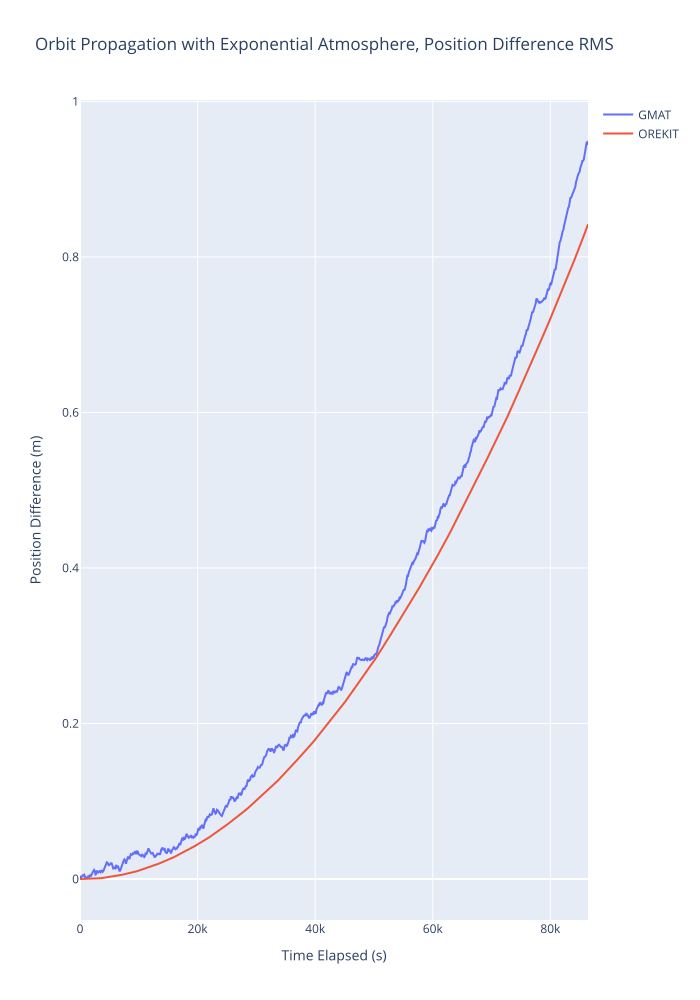

In [16]:
orbit_df_RMS_position_list = [
    ostk_states_compared_df[list_ind][["Elapsed secs", r"${\delta}x$"]]
    for list_ind in range(0, len(all_comparison_states))
]

figure = go.Figure()
figure.update_layout(
    title=f"Orbit Propagation with {title_prefix}, Position Difference RMS",
    showlegend=True,
    height=1000,
)
figure.update_xaxes(title_text="Time Elapsed (s)")
figure.update_yaxes(title_text="Position Difference (m)")

for list_ind, orbit_df_RMS_position in enumerate(orbit_df_RMS_position_list):
    figure.add_trace(
        go.Scatter(
            x=orbit_df_RMS_position["Elapsed secs"],
            y=orbit_df_RMS_position[r"${\delta}x$"],
            name=legend_name_list[list_ind],
            mode="lines",
        )
    )

figure.show("svg")

Plot velocity error

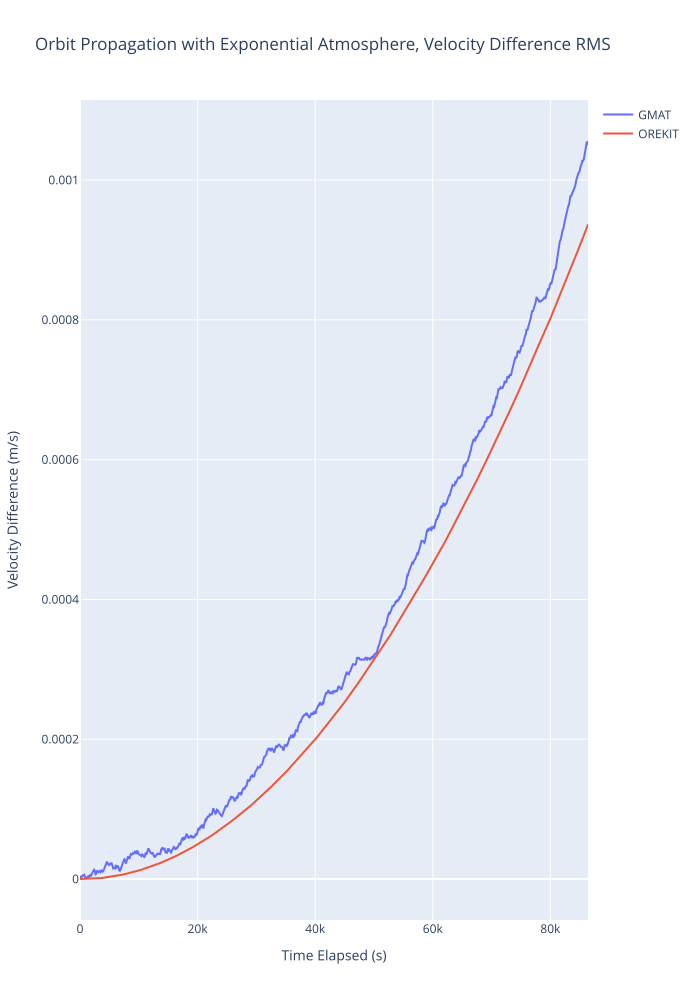

In [17]:
orbit_df_RMS_velocity_list = [
    ostk_states_compared_df[list_ind][["Elapsed secs", r"${\delta}v$"]]
    for list_ind in range(0, len(all_comparison_states))
]

figure = go.Figure()
figure.update_layout(
    title=f"Orbit Propagation with {title_prefix}, Velocity Difference RMS",
    showlegend=True,
    height=1000,
)
figure.update_xaxes(title_text="Time Elapsed (s)")
figure.update_yaxes(title_text="Velocity Difference (m/s)")

for list_ind, orbit_df_RMS_velocity in enumerate(orbit_df_RMS_velocity_list):
    figure.add_trace(
        go.Scatter(
            x=orbit_df_RMS_velocity["Elapsed secs"],
            y=orbit_df_RMS_velocity[r"${\delta}v$"],
            name=legend_name_list[list_ind],
            mode="lines",
        )
    )

figure.show("svg")